# SPICE microstructure products: analysis starter

A starting point for analyses that use the microstructure results from FKt260806 (VMP-250 and VMP-5500). It reads **only the exported products** (`docs/products.md`), never intermediate pipeline outputs, so it can be copied into a separate analysis repository unchanged. Point `SPICE_PRODUCTS` at the products folder.

Rules that keep results defensible (CLAUDE.md, `docs/decisions.md`):

* **Check `product_version`.** Products change only with a version bump and a dated entry in `docs/decisions.md`.
* **Never form diffusivities per window.** T_z and S_z approach zero. Average chi, epsilon and the gradients over windows and profiles first, then divide (section 7).
* **Average arithmetically over profiles; bootstrap over profiles** for intervals. Epsilon and chi are lognormal and intermittent.
* **Flags, not missing data.** Exclusions and cautions are flag variables; select with them explicitly.
* **K_S is a model result.** K_S = R_ρ K_T / γ assumes salt fingers carry the fluxes, and γ (0.5–0.7) is poorly constrained. Carry the γ range through.
* **Don't use K_ρ = 0.2 ε/N² in finger-favourable water** (the density flux is upgradient there).

Sections: 0 setup · 1 casts · 2 segments and QC · 3 mean profiles · 4 diffusivities · 5 finger attribution · 6 per-cast metrics · 7 your own bin averages (including 20–150 m) · 8 template for a tracer (nitrate) flux.

## 0. Setup and provenance

In [25]:
import os
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
import cmocean.cm as cmo    

PRODUCTS = Path(os.environ.get("SPICE_PRODUCTS", "../outputs/recommended")).resolve()
EXPECTED_PRODUCT_VERSION = "0.8"       # update deliberately when you move to newer products
INSTRUMENTS = ["vmp250", "vmp5500"]
LABEL = {"vmp250": "VMP-250", "vmp5500": "VMP-5500"}
COLOR = {"vmp250": "#2a78d6", "vmp5500": "#eb6834"}
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
print(PRODUCTS)

/Users/joegradone/SynologyDrive/Rutgers/Research/code/GitHub/spice_microstructure/outputs/recommended


In [2]:
def load_products(inst: str) -> dict:
    p = {
        "casts": pd.read_csv(PRODUCTS / f"casts_{inst}.csv", parse_dates=["start_utc"]),
        "segments": xr.open_dataset(PRODUCTS / f"segments_{inst}.nc"),
        "binned": xr.open_dataset(PRODUCTS / f"binned_{inst}.nc"),
        "diffusivity": pd.read_csv(PRODUCTS / f"diffusivity_{inst}.csv", dtype={"depth_bin": str}),
        "attribution": pd.read_csv(PRODUCTS / f"attribution_{inst}.csv"),
        "cast_metrics": pd.read_csv(PRODUCTS / f"cast_metrics_{inst}.csv"),
    }
    v = p["segments"].attrs["product_version"]
    if v != EXPECTED_PRODUCT_VERSION:
        warnings.warn(f"{inst}: product_version {v}, expected {EXPECTED_PRODUCT_VERSION}; "
                      "read docs/decisions.md before comparing with earlier results")
    return p


P = {inst: load_products(inst) for inst in INSTRUMENTS}
keys = ["product_version", "run_name", "date_created", "git_commit", "config_sha256",
        "microstructure_tpw_commit", "instrument"]
pd.DataFrame({inst: {k: P[inst]["segments"].attrs.get(k) for k in keys} for inst in INSTRUMENTS})

,vmp250,vmp5500
product_version,0.5,0.5
run_name,fft2_diss8_mle,fft2_diss8_mle
date_created,2026-10-29T16:36:11+00:00,2026-10-29T16:36:11+00:00
git_commit,1625108a14e820888b7f649d284e718fe8457df8-dirty,1625108a14e820888b7f649d284e718fe8457df8-dirty
config_sha256,32f92e5715376bf17b687d71e52d73c04eb1fe0f9b7d2a...,32f92e5715376bf17b687d71e52d73c04eb1fe0f9b7d2a...
microstructure_tpw_commit,c90ff7fefa4c4ab6bd3020ac1b2671e80d9276c4,c90ff7fefa4c4ab6bd3020ac1b2671e80d9276c4
instrument,Rockland VMP-250IR SN 537,Rockland VMP-5500 SN 010


Caveats carried in the products' metadata:

In [3]:
for c in P["vmp5500"]["segments"].attrs["caveats"].split(" | "):
    print("*", c)

* Osborn and Cox assumes local production of thermal variance balances dissipation; lateral (intrusive) finescale gradients can also produce chi (finescale gradient variants are provided).
* The ratio <chi_obs>/<chi_exp> is a dissipation ratio relative to Gamma = 0.2, not a mixing efficiency; in salt fingering the true buoyancy flux is upgradient.
* Shear epsilon near the noise floor is flagged (at_floor) and bounded (epsilon_shear_bounded = max(eps, floor)); flagged windows are kept.
* K_S = R_rho K_T / gamma assumes finger-dominated fluxes; gamma (0.5-0.7) is poorly constrained; K_S is given only where finger-favourable and 1 < R_rho <= diffusivities.k_s_max_r_rho.
* VMP5500 salinity is from each cast's own T-S relation (FP07 temperature); its S_z, R_rho and Turner angle follow the T-S slope, and windows in temperature inversions are flagged ts_salinity_invalid.
* chi depends on the FP07 response model (single pole, speed-dependent tau) by a factor ~1.4-1.8 against a double-pole mode

## 1. Casts

One row per profile: time, position, station (`process_station` or transect), exclusions, cautions, probe serials, Sealog notes. The 48 h process station is at 11.626 N, 50.577 W.

profiles
instrument station                  
vmp250     process_station        15
           transect              122
vmp5500    process_station         4
           transect               40

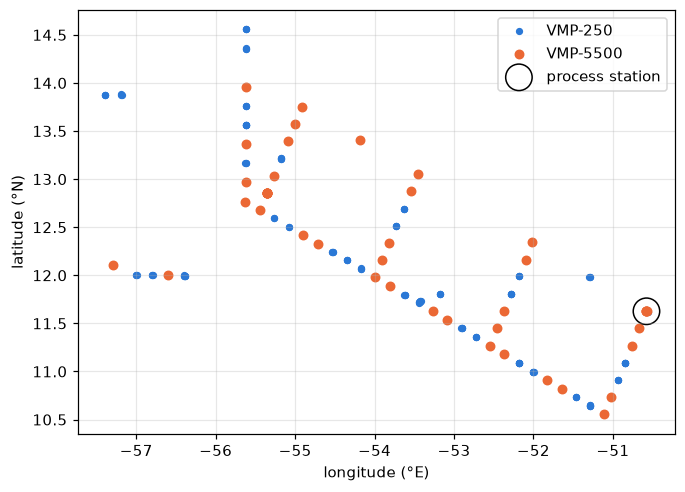

In [4]:
casts = pd.concat([P[i]["casts"] for i in INSTRUMENTS], ignore_index=True)
casts["station"] = casts["station"].fillna("transect")
display(casts.groupby(["instrument", "station"]).size().rename("profiles").to_frame())

fig, ax = plt.subplots(figsize=(7, 5))
for inst in INSTRUMENTS:
    c = P[inst]["casts"]
    ax.scatter(c["lon"], c["lat"], s=14 if inst == "vmp250" else 30, color=COLOR[inst], label=LABEL[inst])
ax.scatter([-50.577], [11.626], s=300, facecolor="none", edgecolor="k", label="process station")
ax.set(xlabel="longitude (°E)", ylabel="latitude (°N)")
ax.legend();

## 2. Segments and QC

`segments_<inst>.nc`: one record per 8 s dissipation window (about 6 m tall, stepped about 3 m). It holds:

* epsilon per probe and combined, plus `epsilon_shear_bounded` = max(ε, noise floor), which is an upper bound where the probe is at its floor;
* chi per thermistor and combined, and `epsilon_T`;
* background hydrography on 10 m fits (`*_10m`);
* the Turner class and staircase labels (`staircase_vdb2021`, `staircase_rollo2022`), and Re_b;
* QC flags.

The selection used by the published averages is `shear_keep` for epsilon and `chi_keep` for chi. `segment_keep` (speed and vibration flags) is a stricter, optional cut; the published averages don't apply it (`segments.enabled: false`).

In [5]:
def segments_df(inst: str) -> pd.DataFrame:
    d = P[inst]["segments"].to_dataframe().reset_index()
    d["instrument"] = inst
    d["cast"] = d["profile_file"].str.split("_prof").str[0]
    return d


def flag_counts(inst: str, var: str) -> pd.Series:
    # Windows with each bit of a QC flag variable set
    v = P[inst]["segments"][var]
    masks = [int(m) for m in str(v.attrs["flag_masks"]).strip("[]").split()]
    names = v.attrs["flag_meanings"].split()
    x = v.values.astype(int)
    return pd.Series({n: int(((x & m) > 0).sum()) for n, m in zip(names, masks)}, name=var)


S = {inst: segments_df(inst) for inst in INSTRUMENTS}
for inst in INSTRUMENTS:
    d = S[inst]
    print(f"{LABEL[inst]}: {len(d)} windows, {d['profile_file'].nunique()} profiles; "
          f"shear_keep {d['shear_keep'].mean():.1%}, chi_keep {d['chi_keep'].mean():.1%}, "
          f"shear at noise floor {d['shear_at_floor'].mean():.1%}")
pd.concat([flag_counts("vmp5500", v) for v in ["segment_flags", "shear_flags", "chi_flags"]], axis=1)

VMP-250: 12206 windows, 135 profiles; shear_keep 97.8%, chi_keep 95.1%, shear at noise floor 19.3%
VMP-5500: 13554 windows, 44 profiles; shear_keep 99.7%, chi_keep 98.7%, shear at noise floor 11.0%


,segment_flags,shear_flags,chi_flags
excluded_cast,0.0,NaN,NaN
near_surface,105.0,NaN,NaN
bottom_approach,27.0,NaN,NaN
speed_range,0.0,NaN,NaN
unsteady_speed,146.0,NaN,NaN
vibration,194.0,NaN,NaN
towyo,0.0,NaN,NaN
no_usable_probe,NaN,45.0,170.0
probe_disagree,NaN,1081.0,547.0
at_floor,NaN,1494.0,458.0


One profile from the process station: turbulence, temperature mixing, and the temperature staircase, coloured by staircase label.

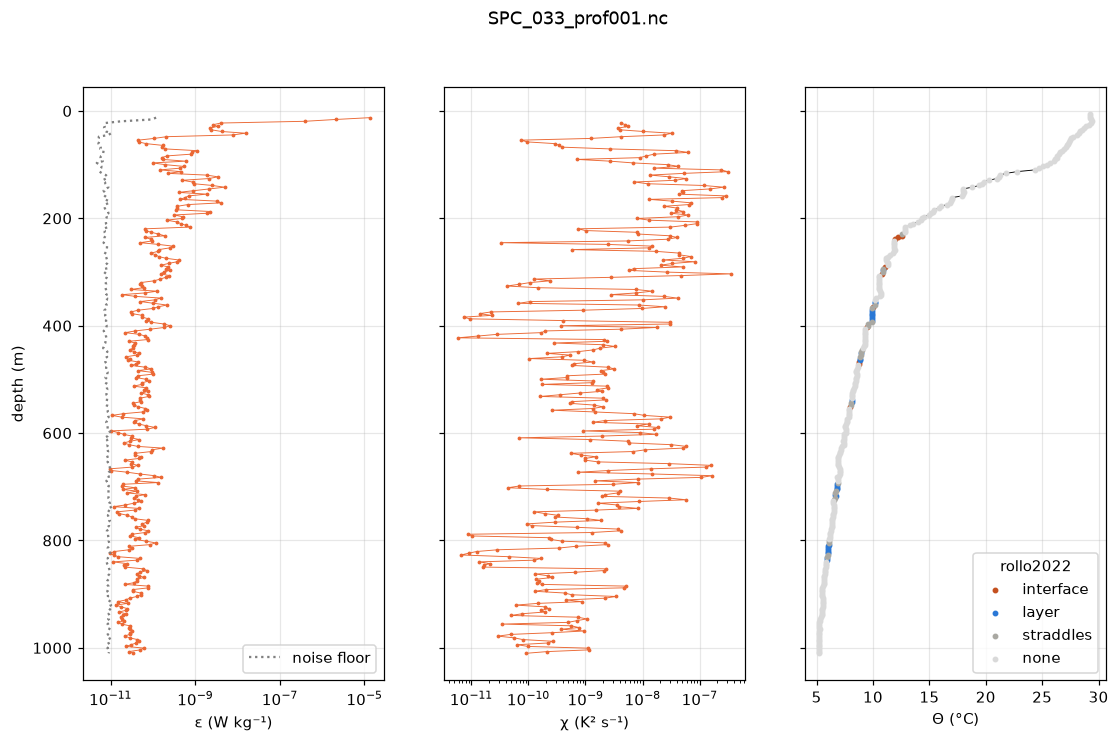

In [6]:
inst = "vmp5500"
d = S[inst]
station_profiles = P[inst]["casts"].query("station == 'process_station'")["profile_file"]
prof = station_profiles.iloc[0]
q = d[d["profile_file"] == prof].sort_values("depth")
lab_color = {"interface": "#c4501f", "layer": "#2a78d6", "straddles": "#a9a8a2", "none": "#d9d9d9"}

fig, axs = plt.subplots(1, 3, figsize=(12, 7), sharey=True)
e = q[q["shear_keep"] == 1]
axs[0].semilogx(e["epsilon_shear_bounded"], e["depth"], ".-", color=COLOR[inst], ms=3, lw=0.6)
axs[0].semilogx(e["epsilon_floor"], e["depth"], ":", color="gray", label="noise floor")
axs[0].set_xlabel("ε (W kg⁻¹)")
axs[0].legend()
c = q[q["chi_keep"] == 1]
axs[1].semilogx(c["chi"], c["depth"], ".-", color=COLOR[inst], ms=3, lw=0.6)
axs[1].set_xlabel("χ (K² s⁻¹)")
axs[2].plot(q["CT"], q["depth"], color="k", lw=0.6)
for lab, col in lab_color.items():
    s = q[q["staircase_rollo2022"] == lab]
    axs[2].scatter(s["CT"], s["depth"], s=8, color=col, label=lab, zorder=3)
axs[2].set_xlabel("Θ (°C)")
axs[2].legend(title="rollo2022")
axs[0].set_ylabel("depth (m)")
axs[0].invert_yaxis()
fig.suptitle(prof);

In [35]:
test

,segment,profile_file,window,pressure,depth,N2_10m,T_z_10m,S_z_10m,alpha,beta,...,kB,chi_flags,chi_at_floor,segment_flags,segment_keep,vibration_ratio,speed_cv,time,instrument,cast
0,0,SPC_004_prof001.nc,0,9.73464,9.9787,0.000337,0.021380,-0.038204,0.000325,0.000717,...,335.1590,32,0,18,0,2.501640,0.071822,2026-08-10 14:50:58.518999517,vmp5500,SPC_004
1,1,SPC_004_prof001.nc,1,11.12670,11.3627,0.000339,0.020500,-0.038916,0.000325,0.000717,...,301.8540,32,0,16,0,2.939710,0.056625,2026-08-10 14:51:02.518743674,vmp5500,SPC_004
2,2,SPC_004_prof001.nc,2,12.64450,12.8717,0.000320,0.018837,-0.036991,0.000325,0.000717,...,280.4880,32,0,48,0,3.267110,0.097972,2026-08-10 14:51:06.518487830,vmp5500,SPC_004
3,3,SPC_004_prof001.nc,3,14.34340,14.5608,0.000376,0.020009,-0.044439,0.000324,0.000717,...,104.5710,32,0,32,0,3.145100,0.031330,2026-08-10 14:51:10.518231988,vmp5500,SPC_004
4,4,SPC_004_prof001.nc,4,16.13050,16.3376,0.000383,0.020183,-0.045289,0.000324,0.000717,...,90.7220,0,0,0,1,2.773230,0.026963,2026-08-10 14:51:14.517976145,vmp5500,SPC_004
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
13549,13549,SPC_063_prof001.nc,306,1002.02000,994.1110,-0.000006,-0.004659,-0.000053,0.000141,0.000754,...,29.3434,2,0,0,1,0.979589,0.000913,2026-08-30 10:44:19.206223625,vmp5500,SPC_063
13550,13550,SPC_063_prof001.nc,307,1005.26000,997.3170,-0.000004,-0.002803,-0.000032,0.000141,0.000754,...,23.4513,0,0,0,1,0.950720,0.000929,2026-08-30 10:44:23.205967782,vmp5500,SPC_063
13551,13551,SPC_063_prof001.nc,308,1008.51000,1000.5300,0.000001,0.000864,0.000010,0.000142,0.000754,...,26.8161,0,0,0,1,0.900392,0.001469,2026-08-30 10:44:27.205711939,vmp5500,SPC_063
13552,13552,SPC_063_prof001.nc,309,1011.76000,1003.7500,0.000004,0.002878,0.000033,0.000142,0.000754,...,17.3875,0,0,0,1,0.916022,0.001858,2026-08-30 10:44:31.205456096,vmp5500,SPC_063


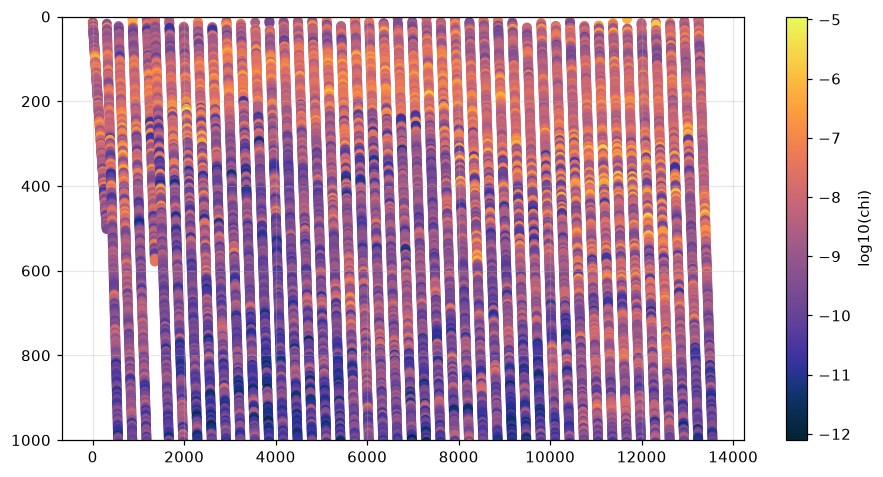

In [37]:
## plot chi in log space
test = S['vmp5500']
plt.figure(figsize=(10, 5))
plt.scatter(np.arange(0,len(np.unique(test['time']))), test['pressure'], c=np.log10(test['chi']), cmap=cmo.thermal, s=30)
#plt.scatter(test['time'], test['pressure'], c=test['chi'], cmap=cmo.thermal, s=30)
plt.ylim(1000,0)
plt.colorbar(label='log10(chi)')



## 3. Mean profiles with bootstrap intervals

`binned_<inst>.nc` has per-profile 5 m bin means (dimensions `profile`, `depth`). Average arithmetically over profiles and resample profiles for the interval. Here the 5 m bins are first averaged to `bin_m` within each profile.

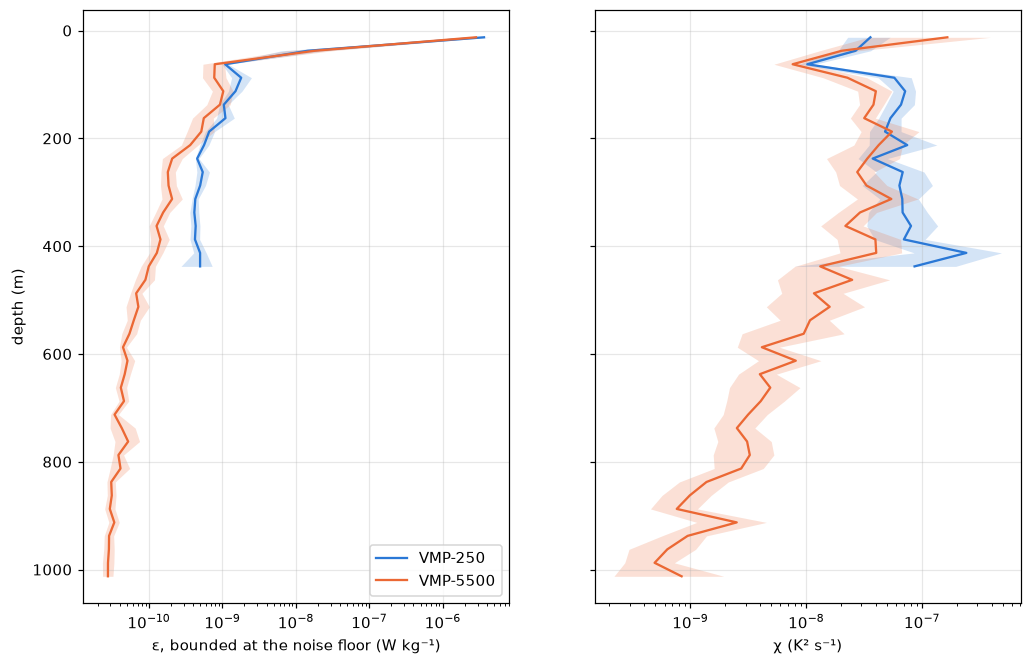

In [7]:
def profile_mean(inst: str, var: str, bin_m: float = 25, n_boot: int = 1000, min_profiles: int = 3,
                 profiles=None, seed: int = 0) -> pd.DataFrame:
    x = P[inst]["binned"][var].to_pandas()                       # profile x depth (5 m)
    if profiles is not None:
        x = x[x.index.isin(profiles)]
    coarse = np.floor(x.columns.to_numpy() / bin_m) * bin_m + bin_m / 2
    per = x.T.groupby(coarse).mean().T                          # profile x coarse bin
    rng = np.random.default_rng(seed)
    idx = rng.integers(0, len(per), size=(n_boot, len(per)))
    arr = per.to_numpy()
    with warnings.catch_warnings():                             # bins empty in a resample
        warnings.simplefilter("ignore", RuntimeWarning)
        boot = np.stack([np.nanmean(arr[i], axis=0) for i in idx])
        out = pd.DataFrame({"depth": per.columns, "mean": np.nanmean(arr, axis=0),
                            "ci_low": np.nanpercentile(boot, 2.5, axis=0),
                            "ci_high": np.nanpercentile(boot, 97.5, axis=0),
                            "n_profiles": per.notna().sum(axis=0).to_numpy()})
    return out[out["n_profiles"] >= min_profiles]


fig, axs = plt.subplots(1, 2, figsize=(11, 7), sharey=True)
for inst in INSTRUMENTS:
    for ax, var in zip(axs, ["epsilon_shear_bounded", "chi"]):
        m = profile_mean(inst, var)
        ax.fill_betweenx(m["depth"], m["ci_low"], m["ci_high"], color=COLOR[inst], alpha=0.2, lw=0)
        ax.plot(m["mean"], m["depth"], color=COLOR[inst], label=LABEL[inst])
axs[0].set(xscale="log", xlabel="ε, bounded at the noise floor (W kg⁻¹)", ylabel="depth (m)")
axs[1].set(xscale="log", xlabel="χ (K² s⁻¹)")
axs[0].invert_yaxis()
axs[0].legend();

## 4. Published diffusivities (20 dbar to the bottom)

`diffusivity_<inst>.csv` (and `.nc`): bin averages over windows and profiles, with 95% bootstrap intervals over profiles. Depth bins run from 20 dbar (`P_top_dbar`, `P_bottom_dbar`; the 20–25 dbar bin is partial). **Pooled records cover 150 dbar to the bottom**, the staircase test range, as the attribution does. Each row is one combination of:

* `instrument_group`: `<inst> all free fall`, `process_station free fall` or `transect free fall`;
* `method`: staircase labels, `vdb2021` or `rollo2022`;
* `turner`: `finger_any`, `strong_finger`, `control` (finger-favourable water outside staircases) or `all_turner`;
* `staircase`: `interface`, `layer`, `straddles`, `none` or `all`;
* `gradients`: `background` (10 m fits), `finescale` (1 m gradient variance) or `interface_local`;
* `depth_bin`: 25 m bin centre, or `pooled`.

`K_S_applicable` and `K_rho_valid` say where those quantities may be used. Above about 150 dbar most water is not finger-favourable: use the `all_turner` records there (K_T from χ, and K_ρ = 0.2⟨ε⟩/⟨N²⟩). Use K_S only from the finger-favourable sets.

In [8]:
def diff(inst: str, group: str = "all free fall", method: str = "rollo2022", turner: str = "finger_any",
         staircase: str = "all", gradients: str = "finescale", pooled: bool = False) -> pd.DataFrame:
    t = P[inst]["diffusivity"]
    q = t[(t["instrument_group"] == f"{inst} {group}") & (t["method"] == method) & (t["turner"] == turner)
          & (t["staircase"] == staircase) & (t["gradients"] == gradients)]
    if pooled:
        return q[q["depth_bin"] == "pooled"]
    q = q[(q["depth_bin"] != "pooled") & q["min_profiles_ok"]].copy()
    q["depth"] = q["depth_bin"].astype(float)
    return q.sort_values("depth")


cols = ["staircase", "n_profiles", "K_T", "K_T_ci_low", "K_T_ci_high", "K_S_g0.65", "K_S_eps_g0.65", "K_GM"]
pd.concat([pd.concat([diff(i, staircase=s, pooled=True) for s in ["all", "interface", "layer", "none"]])
             .assign(instrument=i)[["instrument"] + cols] for i in INSTRUMENTS]).round(8)

,instrument,staircase,n_profiles,K_T,K_T_ci_low,K_T_ci_high,K_S_g0.65,K_S_eps_g0.65,K_GM
168,vmp250,all,127,0.000005,0.000004,0.000006,0.000014,0.000029,0.000003
180,vmp250,interface,32,0.000006,0.000004,0.000009,0.000015,0.000021,0.000003
195,vmp250,layer,40,0.000007,0.000004,0.000013,0.000016,0.000058,0.000002
217,vmp250,none,127,0.000005,0.000004,0.000006,0.000013,0.000028,0.000003
1283,vmp5500,all,44,0.000005,0.000004,0.000006,0.000016,0.000018,0.000002
1344,vmp5500,interface,44,0.000007,0.000005,0.000009,0.000018,0.000011,0.000002
1429,vmp5500,layer,44,0.000004,0.000003,0.000005,0.000014,0.000039,0.000002
1559,vmp5500,none,44,0.000004,0.000004,0.000005,0.000015,0.000018,0.000002


In [ ]:
fig, axs = plt.subplots(1, 2, figsize=(12, 7))
for ax, inst in zip(axs, INSTRUMENTS):
    a = diff(inst, turner="all_turner")             # all water: K_T and K_rho
    f = diff(inst)                                  # finger-favourable water: K_S
    ax.fill_betweenx(a["depth"], a["K_T_ci_low"], a["K_T_ci_high"], color="#2a78d6", alpha=0.2, lw=0)
    ax.plot(a["K_T"], a["depth"], color="#2a78d6", label="K_T, all water")
    ax.plot(a["K_rho"], a["depth"], color="gray", ls=":", label="K_ρ = 0.2⟨ε⟩/⟨N²⟩, all water")
    ks = f[["K_S_g0.5", "K_S_g0.65", "K_S_g0.7"]]
    ax.fill_betweenx(f["depth"], ks.min(axis=1), ks.max(axis=1), color="#eb6834", alpha=0.25, lw=0,
                     label="K_S, γ 0.5–0.7, finger-favourable water")
    ax.plot(f["K_S_g0.65"], f["depth"], color="#eb6834", label="K_S (γ 0.65)")
    ax.plot(a["K_GM"], a["depth"], "k-.", lw=1, label="Garrett–Munk")
    ax.axhline(150, color="k", lw=0.6, ls="--")
    ax.set(xscale="log", xlim=(1e-7, 1e-3), xlabel="diffusivity (m² s⁻¹)", title=LABEL[inst])
    ax.invert_yaxis()
axs[0].set_ylabel("depth (m)")
axs[1].legend(fontsize=8);

## 5. Finger attribution ladder

E = ⟨χ_obs⟩ / ⟨χ_expected⟩ against three baselines:

* Γ = 0.2 theory;
* Garrett–Munk;
* `nonstaircase_control`: finger-favourable water outside staircases at the same depths, matched in Re_b. This gives a lower bound.

The finger fraction is 1 − 1/E. **The spread across baselines is part of the result**, so report it as a range.

In [10]:
att = pd.concat([P[i]["attribution"] for i in INSTRUMENTS])
att = att[att["instrument_group"].str.endswith("all free fall") & (att["method"] == "rollo2022")
          & (att["gradients"] == "finescale")]
att.pivot_table(index=["instrument_group", "staircase"], columns="baseline", values="E").round(2)

baseline                         garrett_munk  nonstaircase_control  \
instrument_group      staircase                                       
vmp250 all free fall  all                1.83                   NaN   
                      interface          2.39                  1.49   
                      layer              3.26                  0.56   
                      none               1.73                   NaN   
vmp5500 all free fall all                2.09                   NaN   
                      interface          2.67                  1.37   
                      layer              2.03                  0.61   
                      none               1.75                   NaN   

baseline                         theory_Gamma0.2  
instrument_group      staircase                   
vmp250 all free fall  all                   1.97  
                      interface             2.76  
                      layer                 1.12  
                      none                  1.90  
vmp5500 all free fall all                   2.86  
                      interface             4.75  
                      layer                 1.45  
                      none                  2.63

## 6. Per-cast metrics (for mesoscale comparisons)

One row per profile: salinity maximum, median R_ρ, staircase coverage, interface counts and jumps, K_T in finger water and its ratio to GM, mean ε and χ.

The two instruments cover different depth ranges (the VMP-250 reaches about 290 m, the VMP-5500 1000 m), so don't pool depth-dependent metrics such as staircase coverage across them.

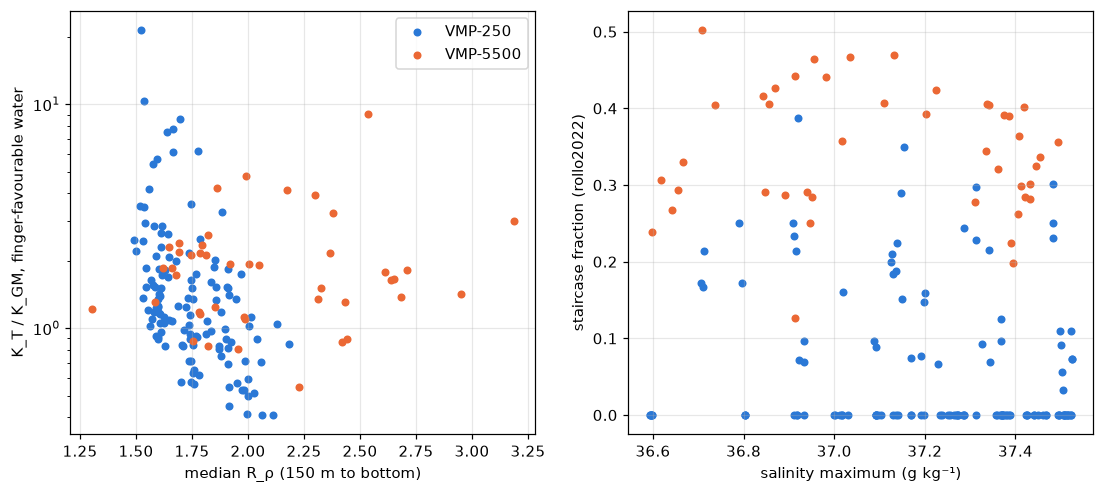

In [11]:
cm = pd.concat([P[i]["cast_metrics"] for i in INSTRUMENTS], ignore_index=True)
fig, axs = plt.subplots(1, 2, figsize=(12, 5))
for inst in INSTRUMENTS:
    c = cm[cm["instrument"] == inst]
    axs[0].scatter(c["R_rho_median"], c["K_T_finger_over_GM"], color=COLOR[inst], label=LABEL[inst], s=18)
    axs[1].scatter(c["SA_max"], c["staircase_fraction_rollo2022"], color=COLOR[inst], label=LABEL[inst], s=18)
axs[0].set(xlabel="median R_ρ (150 m to bottom)", ylabel="K_T / K_GM, finger-favourable water", yscale="log")
axs[1].set(xlabel="salinity maximum (g kg⁻¹)", ylabel="staircase fraction (rollo2022)")
axs[0].legend();

## 7. Your own bin averages

For groupings the published table doesn't have (other bin sizes, a subset of casts, a mesoscale feature), form averages from the segments **the same way**:

1. sum χ, T_z², αT_z, βS_z, ε and N² over the windows of each profile in a bin;
2. sum over profiles;
3. divide;
4. bootstrap by resampling profiles.

Both gradient choices are available: `background` (10 m fits, `T_z_10m`) and `finescale` (1 m gradient variance, `T_z2_fine`, exported since 0.6; R_ρ stays the background value). The first cell checks that both reproduce published bins exactly.

In [ ]:
def window_selection(d: pd.DataFrame, gradients: str) -> pd.Series:
    # Windows used by the published averages (dd_test): both QC keeps, N2 > 0, valid salinity
    ok = ((d["shear_keep"] == 1) & (d["chi_keep"] == 1) & (d["N2_10m"] > 0)
          & np.isfinite(d["T_z_10m"]) & np.isfinite(d["S_z_10m"]) & np.isfinite(d["alpha"])
          & np.isfinite(d["epsilon_shear_bounded"]) & np.isfinite(d["chi"])
          & (d["ts_salinity_invalid"] != 1))
    return ok & np.isfinite(d["T_z2_fine"]) if gradients == "finescale" else ok


def _estimates(s: np.ndarray, gammas) -> dict:
    chi, tz2, atz, bsz, eps, n2, n = s
    kt, rr = chi / (2 * tz2), (atz / bsz if bsz > 0 else np.nan)
    out = {"K_T": kt, "R_rho": rr, "K_rho": 0.2 * eps / n2, "eps_mean": eps / n, "chi_mean": chi / n}
    for g in gammas:
        out[f"K_S_g{g}"] = rr * kt / g if rr > 1 else np.nan
    return out


def bin_diffusivity(d: pd.DataFrame, edges, gradients: str = "finescale", gammas=(0.5, 0.65, 0.7),
                    n_boot: int = 1000, seed: int = 0, min_profiles: int = 3) -> pd.DataFrame:
    # Diffusivities from window sums per profile, in pressure bins (edges in dbar)
    d = d[window_selection(d, gradients)].assign(
        tz2=lambda x: x["T_z2_fine"] if gradients == "finescale" else x["T_z_10m"] ** 2,
        atz=lambda x: x["alpha"] * x["T_z_10m"],
        bsz=lambda x: x["beta"] * x["S_z_10m"], eps=lambda x: x["epsilon_shear_bounded"],
        finger=lambda x: x["turner_class"].isin(["finger", "strong_finger"]))
    d["bin"] = pd.cut(d["pressure"], edges, right=False)
    rng = np.random.default_rng(seed)
    cols = ["chi", "tz2", "atz", "bsz", "eps", "N2_10m"]
    rows = []
    for b, db in d.groupby("bin", observed=True):
        per = db.groupby("profile_file")[cols].sum()
        per["n"] = db.groupby("profile_file").size()
        if len(per) < min_profiles:
            continue
        arr = per.to_numpy()
        r = {"P_low": b.left, "P_high": b.right, "n_windows": len(db), "n_profiles": len(per),
             "finger_fraction": db["finger"].mean(), **_estimates(arr.sum(axis=0), gammas)}
        if n_boot:
            boot = [_estimates(arr[i].sum(axis=0), gammas)["K_T"]
                    for i in rng.integers(0, len(per), (n_boot, len(per)))]
            r["K_T_ci_low"], r["K_T_ci_high"] = np.nanpercentile(boot, [2.5, 97.5])
        rows.append(r)
    return pd.DataFrame(rows)


# Check: reproduce published bins (VMP-5500, all water), both gradient choices
for grad in ["background", "finescale"]:
    for lo in [75, 400]:
        mine = bin_diffusivity(S["vmp5500"], [lo, lo + 25], gradients=grad, n_boot=0).iloc[0]
        pub = diff("vmp5500", turner="all_turner", gradients=grad).query(f"depth_bin == '{lo + 12.5}'").iloc[0]
        print(f"{grad:10s} {lo}-{lo + 25} dbar  K_T mine {mine['K_T']:.4g}  published {pub['K_T']:.4g}")
        assert np.isclose(mine["K_T"], pub["K_T"], rtol=1e-5) and mine["n_windows"] == pub["n_windows"]

Example of a custom grouping: 10 m bins over the upper 300 dbar (the published bins are 25 m). `finger_fraction` shows where the water is finger-favourable. Where it's low, K_ρ = 0.2⟨ε⟩/⟨N²⟩ is the standard estimate and K_T the independent one from χ. **K_S = R_ρ K_T/γ applies only where the water is finger-favourable.** Where K_ρ sits near the noise floor, ε is an upper bound (`epsilon_shear_bounded`).

In [ ]:
edges = np.arange(20, 300 + 1, 10)
upper = {inst: bin_diffusivity(S[inst], edges) for inst in INSTRUMENTS}

fig, axs = plt.subplots(1, 2, figsize=(12, 7), sharey=True)
for ax, inst in zip(axs, INSTRUMENTS):
    u = upper[inst]
    z = (u["P_low"].astype(float) + u["P_high"].astype(float)) / 2
    ax.fill_betweenx(z, u["K_T_ci_low"], u["K_T_ci_high"], color="#2a78d6", alpha=0.2, lw=0)
    ax.plot(u["K_T"], z, color="#2a78d6", label="K_T (finescale gradients)")
    ax.plot(u["K_rho"], z, color="gray", ls=":", label="K_ρ = 0.2⟨ε⟩/⟨N²⟩")
    fz = u["finger_fraction"] > 0.5
    ax.plot(u["K_S_g0.65"].where(fz), z, color="#eb6834", label="K_S (γ 0.65), finger-favourable bins")
    ax.axhline(150, color="k", lw=0.8, ls="--")
    ax.set(xscale="log", xlabel="diffusivity (m² s⁻¹)", title=LABEL[inst])
axs[0].set_ylabel("pressure (dbar)")
axs[0].invert_yaxis()
axs[1].legend(fontsize=8)
upper["vmp5500"].round(8).head(15)

## 8. Template: vertical tracer flux (e.g. nitrate)

F = −K ∂C/∂z (z up), or with depth positive down, the **upward** flux is F_up = K ∂C/∂(depth). In finger-favourable water nitrate behaves like salt (low molecular diffusivity), so use K_S with its γ range; elsewhere use K_ρ or K_T.

Your tracer data don't come into this repository. Load them in the analysis repository, interpolate the gradient onto the diffusivity depths, and keep the K uncertainty (bootstrap interval and γ range) attached.

In [14]:
def upward_flux(k_depth, k_value, c_depth, c_value):
    # Upward flux K dC/d(depth) at the diffusivity depths; units of K times C per m
    # (e.g. m2 s-1 x mmol m-3 / m = mmol m-2 s-1). Positive = upward.
    c_depth, c_value = np.asarray(c_depth, float), np.asarray(c_value, float)
    order = np.argsort(c_depth)
    dcdz = np.gradient(c_value[order], c_depth[order])
    return np.asarray(k_value, float) * np.interp(k_depth, c_depth[order], dcdz, left=np.nan, right=np.nan)


# Example, once you have a nitrate profile (depth in m, NO3 in mmol m-3):
# no3 = pd.read_csv("path/to/nitrate_profile.csv")
# q = diff("vmp5500", group="process_station free fall")
# for g in ["0.5", "0.65", "0.7"]:
#     q[f"F_NO3_g{g}"] = upward_flux(q["depth"], q[f"K_S_g{g}"], no3["depth"], no3["NO3"]) * 86400   # mmol m-2 d-1

## 9. Per-window finger diffusivities in single profiles (`finger_profiles_<inst>.nc`, products 0.8+)

One record per 8 s dissipation window (about 6 m tall, about 3 m apart) in each profile, from 20 dbar. Nothing is averaged over profiles or windows: this is the native resolution of the microstructure data, for salt-finger nitrate fluxes with a ~1 m nitrate sensor.

* `K_T` = χ / (2 `T_z2_fine`): heat diffusivity on 1 m gradients.
* `K_rho` = 0.2 ε / N²: the shear-turbulence diffusivity (an upper bound where shear ε is at its noise floor).
* `K_S` = R_ρ K_T / γ (γ 0.65; `K_S_gamma_low`/`_high` at γ 0.7/0.5): salt (nitrate) diffusivity if all of χ is finger-driven. Only in finger-favourable windows with 1 < R_ρ ≤ 4 and valid salinity.
* `K_S_finger` = R_ρ max(K_T − K_rho, 0) / γ: the finger-driven part, after removing the χ shear turbulence would produce. 0 where there is no excess; a lower bound where shear ε is at its floor.
* `finger_flags`: bit flags (`flag_meanings` attribute), e.g. `weak_gradient` (staircase mixed layers, where K can spike) and `shear_at_floor`.

Two cautions:

* **Single windows are snapshots of patchy mixing.** K varies by about ×3 from one window to the next (`K_T_window_sd_ln`), far more than the FP07 measurement scatter (`chi_pair_sd_ln`). There is no per-window confidence interval.
* **Never average the per-window K.** Average χ, `T_z2_fine`, ε and N² (and αT_z, βS_z for R_ρ) over windows first, then form K (the `average_finger` function below). The mean of per-window K_T is several times too high, because a few weak-gradient windows dominate. Averaging per-window *fluxes* is fine when dN/dz is measured in each window.

In [ ]:
FP = {inst: xr.open_dataset(PRODUCTS / f"finger_profiles_{inst}.nc") for inst in INSTRUMENTS}
for inst, ds in FP.items():
    a = ds.attrs
    print(f"{LABEL[inst]}: product_version {a['product_version']}, {ds.sizes['window_record']} windows in "
          f"{len(np.unique(ds['profile_file']))} profiles; FP07 pair scatter sd(ln chi) {a['chi_pair_sd_ln']:.2f}, "
          f"window-to-window sd(ln K_T) {a['K_T_window_sd_ln']:.2f}")

FLAG_BITS = dict(zip(FP["vmp5500"]["finger_flags"].attrs["flag_meanings"].split(),
                     [int(m) for m in np.atleast_1d(FP["vmp5500"]["finger_flags"].attrs["flag_masks"])]))


def finger_df(inst: str) -> pd.DataFrame:
    return FP[inst].to_dataframe().reset_index(drop=True).sort_values(["profile_file", "pressure"])


def has_flag(d: pd.DataFrame, name: str) -> pd.Series:
    return (d["finger_flags"].astype(int) & FLAG_BITS[name]) > 0


F = {inst: finger_df(inst) for inst in INSTRUMENTS}
print(FLAG_BITS)

In [ ]:
def plot_finger_profile(inst: str, profile_file: str):
    q = F[inst][F[inst]["profile_file"] == profile_file]
    fig, axs = plt.subplots(1, 3, figsize=(12, 7), sharey=True, gridspec_kw={"width_ratios": [2.2, 1, 1]})
    ax = axs[0]
    ax.semilogx(q["K_T"], q["pressure"], ".-", color="0.6", lw=0.6, ms=3, label="K_T (heat, 1 m gradients)")
    ax.semilogx(q["K_S"], q["pressure"], "o", color="#eb6834", ms=3.5, label="K_S (all χ finger-driven)")
    ax.semilogx(q["K_S_finger"].where(q["K_S_finger"] > 0), q["pressure"], "s", mfc="none", color="#1f5fa8", ms=4,
                label="K_S_finger (turbulence removed)")
    ax.semilogx(q["K_rho"], q["pressure"], "-", color="k", lw=0.8, label="K_ρ = 0.2ε/N²")
    weak = has_flag(q, "weak_gradient")
    ax.semilogx(q.loc[weak, "K_T"], q.loc[weak, "pressure"], "x", color="r", ms=5, label="weak_gradient")
    ax.set(xlim=(1e-8, 1e-2), xlabel="diffusivity (m²/s)", ylabel="pressure (dbar)")
    ax.legend(fontsize=8, loc="lower left")
    axs[1].plot(q["R_rho_10m"].clip(0, 6), q["pressure"], color="k", lw=0.8)
    axs[1].axvspan(1, 4, color="#eb6834", alpha=0.1)
    axs[1].set(xlim=(0, 6), xlabel="R_ρ (10 m)")
    axs[2].plot(q["turner_angle_10m"], q["pressure"], color="0.3", lw=0.8)
    axs[2].axvspan(45, 90, color="#eb6834", alpha=0.1)
    for p in q.loc[q["staircase_rollo2022"] == "interface", "pressure"]:
        axs[2].axhline(p, color="#1f5fa8", lw=0.5, alpha=0.5)
    axs[2].set(xlim=(-90, 90), xlabel="Turner angle (°)")
    axs[0].invert_yaxis()
    fig.suptitle(f"{LABEL[inst]} {profile_file.replace('.nc', '')}: per-window diffusivities "
                 "(blue lines: staircase interfaces)")
    fig.tight_layout()
    return fig


inst = "vmp5500"
pf = next((p for p in F[inst]["profile_file"].unique() if p.startswith("SPC_039")), F[inst]["profile_file"].iloc[0])
plot_finger_profile(inst, pf);

### Averaging down a single profile (or over profiles), done correctly

`average_finger` forms K from window averages of the ingredients over any depth edges: K_T = ⟨χ⟩ / (2⟨T_z2_fine⟩), R_ρ = ⟨αT_z⟩ / ⟨βS_z⟩, K_ρ = 0.2⟨ε⟩/⟨N²⟩, K_S = R_ρ K_T / γ and K_S_finger = R_ρ max(K_T − K_ρ, 0) / γ. By default it uses only finger-favourable windows with valid χ and salinity. Pass one profile for a single-profile profile at your chosen resolution, or several for a group average. The comparison below shows how far the naive mean of per-window K_T is from the ratio of averages.

In [ ]:
GAMMA = float(FP["vmp5500"].attrs["gamma"])
GAMMA_FLUX = float(FP["vmp5500"].attrs["flux_coefficient"])
R_RHO_MAX = float(FP["vmp5500"].attrs["r_rho_max"])


def average_finger(d: pd.DataFrame, edges, finger_only: bool = True, gamma: float = GAMMA) -> pd.DataFrame:
    q = d[(d["chi_keep"] == 1) & np.isfinite(d["chi"]) & (d["T_z2_fine"] > 0)].copy()
    if finger_only:
        q = q[~has_flag(q, "not_finger_favourable") & ~has_flag(q, "ts_salinity_invalid")]
    q["aTz"], q["bSz"] = q["alpha"] * q["T_z_10m"], q["beta"] * q["S_z_10m"]
    q["bin"] = pd.cut(q["pressure"], edges)
    g = q.groupby("bin", observed=True)
    out = g.agg(P_top=("pressure", "min"), P_bottom=("pressure", "max"), n_windows=("chi", "size"),
                n_profiles=("profile_file", "nunique"), chi=("chi", "mean"), T_z2=("T_z2_fine", "mean"),
                eps=("epsilon_shear_bounded", "mean"), N2=("N2_10m", "mean"), aTz=("aTz", "mean"),
                bSz=("bSz", "mean"), K_T_naive=("K_T", "mean"))
    out["K_T"] = out["chi"] / (2 * out["T_z2"])
    out["R_rho"] = out["aTz"] / out["bSz"]
    out["K_rho"] = np.where(out["N2"] > 0, GAMMA_FLUX * out["eps"] / out["N2"], np.nan)
    ok = (out["R_rho"] > 1) & (out["R_rho"] <= R_RHO_MAX)
    out["K_S"] = np.where(ok, out["R_rho"] * out["K_T"] / gamma, np.nan)
    out["K_S_finger"] = np.where(ok, out["R_rho"] * np.clip(out["K_T"] - out["K_rho"], 0, None) / gamma, np.nan)
    out["depth_mid"] = [b.mid for b in out.index]
    return out.reset_index(drop=True)


# one profile at 20 m resolution, against the per-window values
one = F[inst][F[inst]["profile_file"] == pf]
avg = average_finger(one, np.arange(20, 1020, 20))
fig, ax = plt.subplots(figsize=(6, 7))
ax.semilogx(one["K_S"], one["pressure"], "o", color="#eb6834", ms=2.5, alpha=0.5, label="K_S per window")
ax.semilogx(avg["K_S"], avg["depth_mid"], "-", color="#eb6834", lw=2, label="K_S, 20 m ratio of averages")
ax.semilogx(avg["K_S_finger"].where(avg["K_S_finger"] > 0), avg["depth_mid"], "--", color="#1f5fa8", lw=2,
            label="K_S_finger, 20 m (gaps: no finger excess)")
ax.set(xlabel="diffusivity (m²/s)", ylabel="pressure (dbar)", title=f"{LABEL[inst]} {pf.replace('.nc', '')}")
ax.invert_yaxis()
ax.legend(fontsize=8)

# the naive mean of per-window K_T against the ratio of averages, finger water 150 dbar and below
for i in INSTRUMENTS:
    a = average_finger(F[i], [150, 1100]).iloc[0]
    print(f"{LABEL[i]}: K_T ratio of averages {a['K_T']:.2g}; mean of per-window K_T {a['K_T_naive']:.2g} "
          f"({a['K_T_naive'] / a['K_T']:.1f}x too high)")

In [ ]:
# Per-window finger nitrate flux, once you have a ~1 m nitrate profile from the same cast
# (depth in m, NO3 in mmol m-3). upward_flux (section 8) interpolates dNO3/d(depth) onto the
# window depths; K_S_finger gives the finger-driven part, K_S the upper estimate.
# no3 = pd.read_csv("path/to/SPC_039_suna.csv")
# q = F["vmp5500"][F["vmp5500"]["profile_file"] == "SPC_039_prof001.nc"].copy()
# for k in ["K_S", "K_S_finger", "K_S_gamma_low", "K_S_gamma_high"]:
#     q[f"F_{k}"] = upward_flux(q["depth"], q[k], no3["depth"], no3["NO3"]) * 86400   # mmol m-2 d-1, + = upward
# The gradient should be over the same window (about 6 m): smooth the nitrate profile to the window height
# (fall_speed x 8 s) before differentiating, or the 1 m sensor noise enters the flux.

## Notes

* Methods and their reasons: `docs/decisions.md`. Variable definitions: `docs/products.md`. Rerun the products: `python src/run_pipeline.py --config config/config.yaml --sensitivity fft2_diss8_mle`.
* Largest processing systematics on K_S: the FP07 response model (about 2×) and γ (1.4×). Sensitivity runs are summarised in `sensitivity_summary.csv` in the products folder.
* Staircase labels: `rollo2022` (tuned) is used above; `vdb2021` (published thresholds) is the alternative and labels fewer windows.